In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
from datetime import timedelta
%matplotlib inline
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import math
sns.set_theme()
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

from __future__ import annotations

from typing import Any

try:
    import xgboost as xgb
except ImportError:  # pragma: no cover
    xgb = None

In [2]:
df_ori = pd.read_excel("Online Retail.xlsx")

In [3]:
df_ori.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
df_ori.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
# check for  cancel invoice
df_ori[df_ori['InvoiceNo'].apply(lambda x: str(x).startswith("C"))]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [6]:
bool_error = (df_ori['Quantity']<=0) | (df_ori['UnitPrice']<=0)
print('With Quantity negative and UnitPrice negative:', df_ori[(df_ori['Quantity']<0) & (df_ori['UnitPrice']<0)].shape[0])
print('With Quantity or UnitPrice negative or equals to zero:', df_ori[bool_error].shape[0])
print('Values errors by percentage:', str(df_ori[bool_error].shape[0]/df_ori.shape[0]*100)[:5], '%')
print('CustomerIDs with these anomalous values are:', df_ori[bool_error]['CustomerID'].unique())

With Quantity negative and UnitPrice negative: 0
With Quantity or UnitPrice negative or equals to zero: 11805
Values errors by percentage: 2.178 %
CustomerIDs with these anomalous values are: [14527. 15311. 17548. ... 12985. 15951. 16446.]


In [7]:
df_ori = df_ori[~(bool_error | df_ori['CustomerID'].isnull())]

In [8]:
df_ori.info()

<class 'pandas.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397884 non-null  object        
 1   StockCode    397884 non-null  object        
 2   Description  397884 non-null  object        
 3   Quantity     397884 non-null  int64         
 4   InvoiceDate  397884 non-null  datetime64[us]
 5   UnitPrice    397884 non-null  float64       
 6   CustomerID   397884 non-null  float64       
 7   Country      397884 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 27.3+ MB


In [9]:
df_ori.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [10]:
df_ori.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,397884.000000,397884,397884.000000,397884.000000
mean,12.988238,2011-07-10 23:41:23.511023,3.116488,15294.423453
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000
25%,2.000000,2011-04-07 11:12:00,1.250000,13969.000000
50%,6.000000,2011-07-31 14:39:00,1.950000,15159.000000
75%,12.000000,2011-10-20 14:33:00,3.750000,16795.000000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000
std,179.331775,NaN,22.097877,1713.141560


In [11]:
df_ori['CustomerID'] = df_ori['CustomerID'].astype('int32')
df_ori['Amount'] = df_ori['UnitPrice']*df_ori['Quantity']

In [12]:
valid_dates = df_ori['InvoiceDate']
max_month = valid_dates.dt.to_period("M").max()
holdout_start = (max_month - 2).to_timestamp()
holdout_end = valid_dates.max()
holdout_start,holdout_end

(Timestamp('2011-10-01 00:00:00'), Timestamp('2011-12-09 12:50:00'))

In [13]:
historical = df_ori.loc[df_ori["InvoiceDate"] < holdout_start].copy()

In [14]:
#Extract features for each customer
data_process = historical.groupby(['CustomerID']).agg({
        'InvoiceDate': lambda x: (holdout_start - x.max()).days,
        # 'InvoiceNo': 'count',
        'InvoiceNo': 'nunique',
        'Amount': 'sum'})

#renaming
data_process.columns = ['Recency', 'Frequency', 'MonetaryValue']

data_process

,Recency,Frequency,MonetaryValue
CustomerID,,,
12346,255,1,77183.60
12347,59,5,2790.86
12348,5,4,1797.24
12350,240,1,334.40
12352,2,7,2194.31
...,...,...,...
18280,207,1,180.60
18281,110,1,80.82
18282,56,1,100.21


In [15]:
data_process.describe()

,Recency,Frequency,MonetaryValue
count,3616.000000,3616.000000,3616.000000
mean,91.895188,3.641593,1712.411212
std,86.843755,6.121759,7024.622861
min,0.000000,1.000000,2.900000
25%,18.000000,1.000000,284.030000
50%,63.000000,2.000000,599.825000
75%,148.000000,4.000000,1440.900000
max,303.000000,139.000000,203106.640000


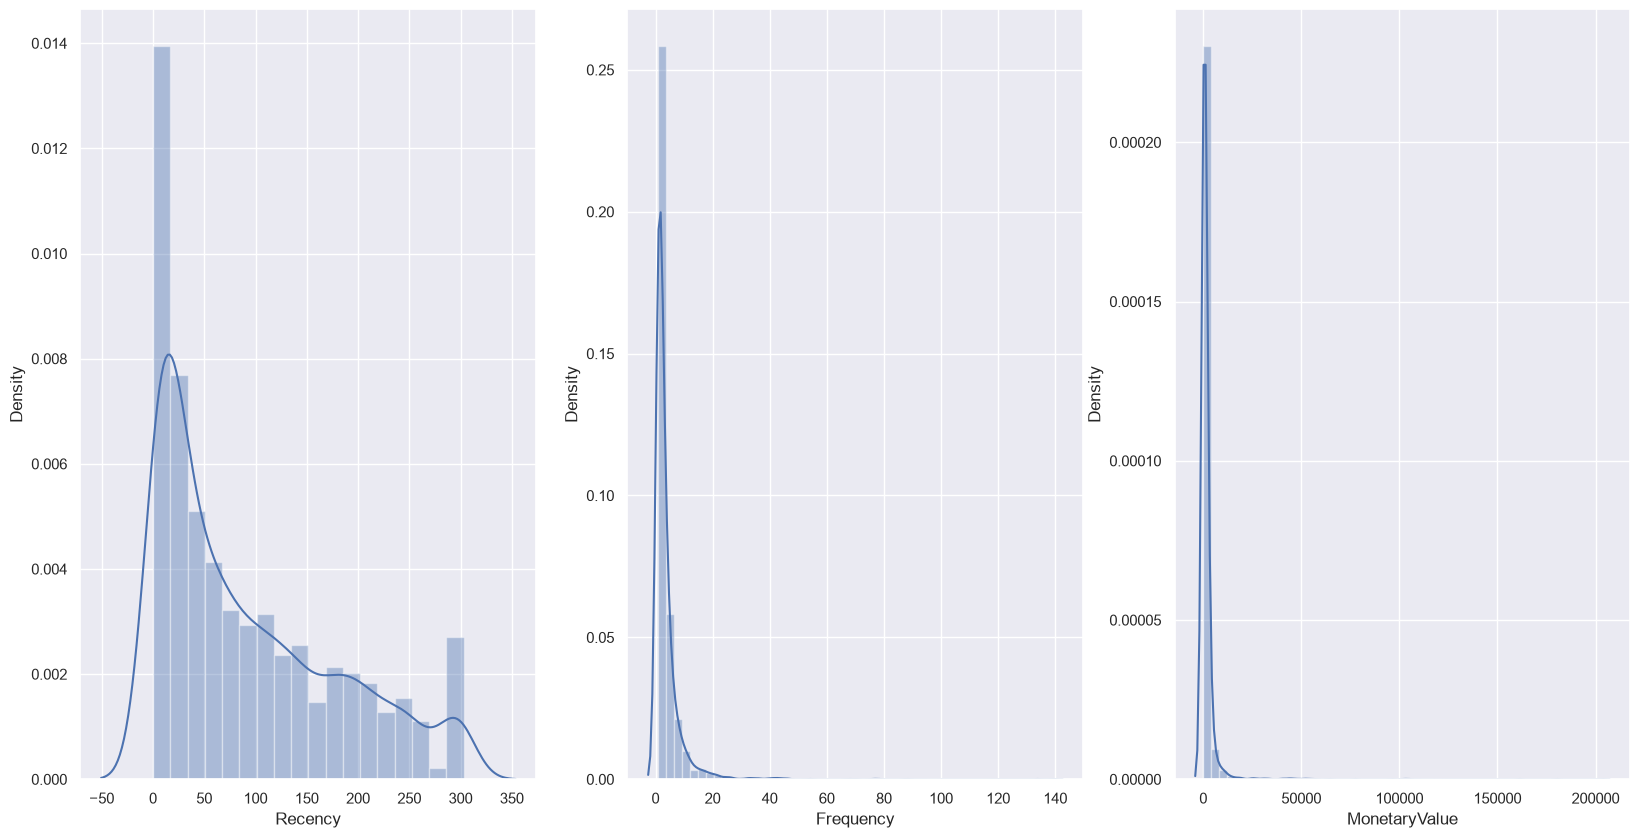

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
for i, feature in enumerate(list(data_process.columns)):
    sns.distplot(data_process[feature], ax=axes[i])

In [17]:
# import skew
from scipy.stats import skew
print('Skewness for Recency:', skew(data_process['Recency']))
print('Skewness for Frequency:', skew(data_process['Frequency']))
print('Skewness for MonetaryValue:', skew(data_process['MonetaryValue']))


Skewness for Recency: 0.8766699895525222
Skewness for Frequency: 9.7420165377446
Skewness for MonetaryValue: 18.145613327856736


The data is skewed. Using log transformation we can improve the quality of the data 

In [18]:
data_process['Recency_sqrt'] = np.sqrt(data_process['Recency'])
data_process['Frequency_log'] = np.log1p(data_process['Frequency'])
data_process['MonetaryValue_log'] = np.log1p(data_process['MonetaryValue'])
data_process[:3]

,Recency,Frequency,MonetaryValue,Recency_sqrt,Frequency_log,MonetaryValue_log
CustomerID,,,,,,
12346,255,1,77183.60,15.968719,0.693147,11.253955
12347,59,5,2790.86,7.681146,1.791759,7.934463
12348,5,4,1797.24,2.236068,1.609438,7.494564


<Axes: xlabel='MonetaryValue_log', ylabel='Density'>

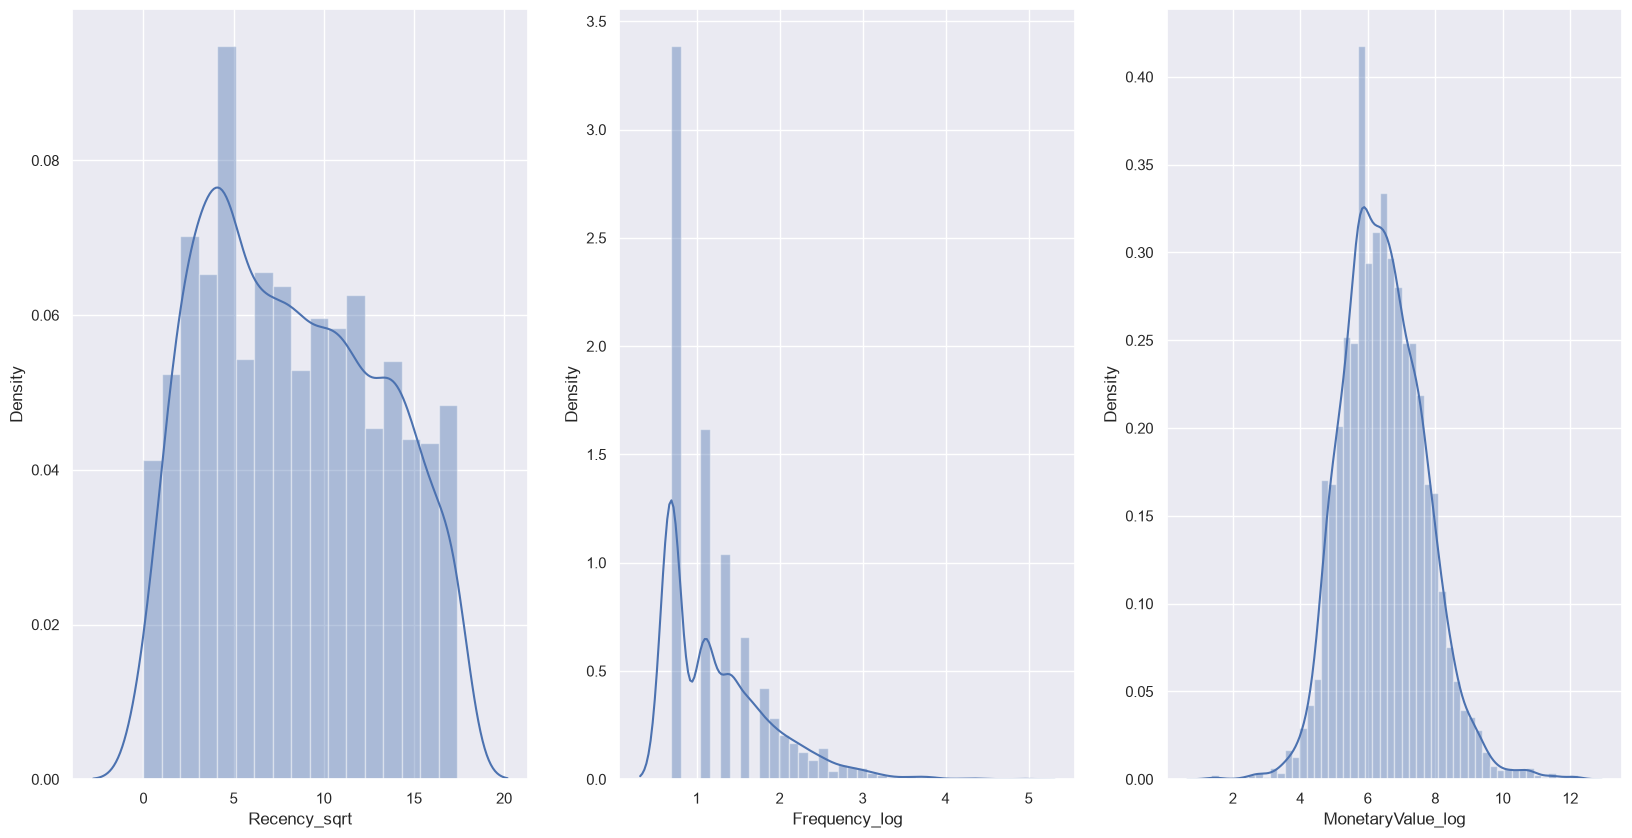

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
sns.distplot(data_process['Recency_sqrt'], ax=axes[0])
sns.distplot(data_process['Frequency_log'], ax=axes[1])
sns.distplot(data_process['MonetaryValue_log'], ax=axes[2])


In [20]:
# skewness after log and sqrt transformation
print('Skewness for Recency_sqrt:', skew(data_process['Recency_sqrt']))
print('Skewness for Frequency_log:', skew(data_process['Frequency_log']))
print('Skewness for MonetaryValue_log:', skew(data_process['MonetaryValue_log']))


Skewness for Recency_sqrt: 0.2038334759813095
Skewness for Frequency_log: 1.344601606643593
Skewness for MonetaryValue_log: 0.3987910916773369


In [21]:
def create_future_purchase_target(
    customer_features: pd.DataFrame,
    valid_transactions: pd.DataFrame,
    holdout_start: pd.Timestamp,
    holdout_end: pd.Timestamp,
) -> pd.DataFrame:
    """Label each historical customer by whether they purchased in the final holdout window."""
    future_transactions = valid_transactions.loc[
        (valid_transactions["InvoiceDate"] >= holdout_start) & (valid_transactions["InvoiceDate"] <= holdout_end)
    ].copy()

    future_customer_purchases = (
        future_transactions.groupby("CustomerID")["InvoiceNo"].nunique().rename("future_invoice_count")
    )

    labelled = customer_features.merge(
        future_customer_purchases.reset_index(),
        on="CustomerID",
        how="left",
    )
    labelled["future_invoice_count"] = labelled["future_invoice_count"].fillna(0).astype(int)
    labelled["FuturePurchase"] = (labelled["future_invoice_count"] > 0).astype(int)

    return labelled

model_df = create_future_purchase_target(data_process, df_ori, holdout_start, holdout_end)


In [22]:
model_df.columns

Index(['CustomerID', 'Recency', 'Frequency', 'MonetaryValue', 'Recency_sqrt',
       'Frequency_log', 'MonetaryValue_log', 'future_invoice_count',
       'FuturePurchase'],
      dtype='str')

In [23]:
model_df.FuturePurchase.value_counts()

FuturePurchase
1    1838
0    1778
Name: count, dtype: int64

<Axes: xlabel='FuturePurchase', ylabel='count'>

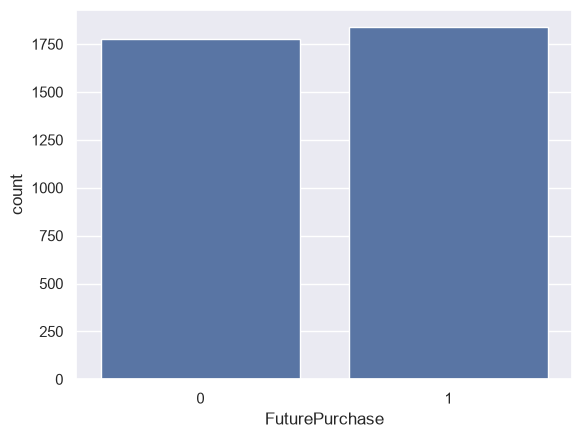

In [48]:
sns.countplot(data=
model_df, x='FuturePurchase')



Target No data imbalance

In [25]:
 
TARGET_COL = "FuturePurchase"
train_df, test_df = train_test_split(
        model_df,
        test_size=0.20,
        random_state=42,
        stratify=model_df[TARGET_COL],
    )


Normalize data for model training

In [26]:
list_input = ['Recency_sqrt','Frequency_log','MonetaryValue_log']
minmax = MinMaxScaler()
for col in list_input:
    train_df[col] = minmax.fit_transform(train_df[[col]])

    test_df[col] = minmax.transform(test_df[[col]])


In [27]:
train_df

,CustomerID,Recency,Frequency,MonetaryValue,Recency_sqrt,Frequency_log,MonetaryValue_log,future_invoice_count,FuturePurchase
1930,15453,22,4,712.80,0.269457,0.215674,0.479685,3,1
1055,14032,17,7,2147.57,0.236866,0.326302,0.581149,4,1
2458,16338,87,1,214.80,0.535844,0.000000,0.369538,0,0
2814,16928,10,17,2847.60,0.181668,0.517177,0.607117,0,0
2450,16323,126,1,207.50,0.644858,0.000000,0.366370,0,0
...,...,...,...,...,...,...,...,...,...
2263,16023,122,2,500.69,0.634539,0.095437,0.447217,1,1
2279,16049,5,1,488.26,0.128459,0.000000,0.444907,2,1
1014,13963,238,4,664.54,0.886272,0.215674,0.473239,0,0
2069,15689,49,2,254.10,0.402139,0.095437,0.384943,0,0


In [29]:
SSE, max_k = [], 15
results =[]
train_X= train_df[list_input]
for k in range(1,max_k):
    kmeans = KMeans(n_clusters=k+1, random_state=42).fit(train_X)
    SSE.append(kmeans.inertia_)
    labels = kmeans.predict(train_X)
    score = silhouette_score(train_X, labels)
    db = davies_bouldin_score(train_X, labels)
    ch = calinski_harabasz_score(train_X, labels)
    counts = pd.Series(labels).value_counts().sort_index()
    results.append({
        "k": k+1,
        "silhouette": score,
        "davies_bouldin": db,
        "calinski_harabasz": ch,
        "cluster_counts": counts.to_dict(),
        "n_small_clusters": int((counts < max(5, 0.02 * len(train_X))).sum()),
    })

fig = go.Figure(data=go.Scatter(x=list(range(1, max_k+1)), y=SSE, ))
fig.update_traces(marker_size=14)
fig.show()

In [30]:
pd.DataFrame(results)

,k,silhouette,davies_bouldin,calinski_harabasz,cluster_counts,n_small_clusters
0,2,0.478933,0.764343,3931.094606,"{0: 1576, 1: 1316}",0
1,3,0.390145,0.984612,3216.804123,"{0: 619, 1: 1163, 2: 1110}",0
2,4,0.374545,0.889168,3296.749483,"{0: 895, 1: 788, 2: 655, 3: 554}",0
3,5,0.352255,0.932378,3076.817157,"{0: 512, 1: 681, 2: 614, 3: 367, 4: 718}",0
4,6,0.327204,0.954028,2877.982913,"{0: 467, 1: 575, 2: 551, 3: 319, 4: 382, 5: 598}",0
5,7,0.317208,0.968815,2789.819938,"{0: 392, 1: 526, 2: 490, 3: 129, 4: 392, 5: 56...",0
6,8,0.307910,0.974463,2694.253713,"{0: 383, 1: 443, 2: 338, 3: 179, 4: 385, 5: 40...",0
7,9,0.298392,1.023472,2581.791138,"{0: 370, 1: 409, 2: 307, 3: 254, 4: 365, 5: 35...",0
8,10,0.283717,1.030056,2489.485309,"{0: 329, 1: 400, 2: 304, 3: 233, 4: 325, 5: 29...",0
9,11,0.279924,1.071168,2400.436114,"{0: 229, 1: 378, 2: 288, 3: 210, 4: 310, 5: 31...",0


In [ ]:
sns.scatterplot(data=pd.DataFrame(results),x="K",y=)

In [31]:
model =  KMeans(n_clusters=2, random_state=42).fit(train_X)
train_X['cluster'] = model.predict(train_X)
fig = px.scatter_3d(train_X, x=list_input[0], y=list_input[1], z=list_input[2],
              color='cluster')
fig.show()

In [32]:
train_df.loc[train_X.index, "cluster"] = train_X["cluster"]

In [33]:
train_df

,CustomerID,Recency,Frequency,MonetaryValue,Recency_sqrt,Frequency_log,MonetaryValue_log,future_invoice_count,FuturePurchase,cluster
1930,15453,22,4,712.80,0.269457,0.215674,0.479685,3,1,0.0
1055,14032,17,7,2147.57,0.236866,0.326302,0.581149,4,1,0.0
2458,16338,87,1,214.80,0.535844,0.000000,0.369538,0,0,1.0
2814,16928,10,17,2847.60,0.181668,0.517177,0.607117,0,0,0.0
2450,16323,126,1,207.50,0.644858,0.000000,0.366370,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...
2263,16023,122,2,500.69,0.634539,0.095437,0.447217,1,1,1.0
2279,16049,5,1,488.26,0.128459,0.000000,0.444907,2,1,0.0
1014,13963,238,4,664.54,0.886272,0.215674,0.473239,0,0,1.0
2069,15689,49,2,254.10,0.402139,0.095437,0.384943,0,0,0.0


In [34]:
test_x = test_df[list_input]
test_x['cluster'] = model.predict(test_x)
fig = px.scatter_3d(test_x, x=list_input[0], y=list_input[1], z=list_input[2],
              color='cluster')
fig.show()

In [35]:
test_df.loc[test_x.index, "cluster"] = test_x["cluster"]

In [36]:
test_df

,CustomerID,Recency,Frequency,MonetaryValue,Recency_sqrt,Frequency_log,MonetaryValue_log,future_invoice_count,FuturePurchase,cluster
1620,14962,200,1,126.70,0.812444,0.000000,0.321229,0,0,1.0
3288,17731,9,4,1240.11,0.172345,0.215674,0.530618,0,0,0.0
2106,15749,165,3,44534.30,0.737939,0.163151,0.860278,0,0,1.0
2868,17027,8,6,890.29,0.162489,0.294872,0.500132,0,0,0.0
3016,17289,110,1,167.36,0.602525,0.000000,0.346680,2,1,1.0
...,...,...,...,...,...,...,...,...,...,...
2103,15745,3,2,607.75,0.099504,0.095437,0.465027,2,1,0.0
260,12735,245,2,779.57,0.899211,0.095437,0.487919,0,0,1.0
2467,16351,262,1,153.90,0.929885,0.000000,0.339008,0,0,1.0
189,12639,168,1,486.10,0.744618,0.000000,0.444499,0,0,1.0


In [37]:
fig = px.scatter_3d(test_df, x='Recency', y='Frequency', z='MonetaryValue',
              color='cluster')
fig.show()

#### segement mapping

In [38]:
segment_map = {
    1: "Inactive/Low-Value",
    0: "Loyal/High-Value"
}

In [39]:
train_df["segment_name"] = train_df["cluster"].map(segment_map)
test_df["segment_name"] = test_df["cluster"].map(segment_map)

In [40]:
train_df.segment_name.value_counts()

segment_name
Loyal/High-Value      1576
Inactive/Low-Value    1316
Name: count, dtype: int64

In [41]:
train_df.columns

Index(['CustomerID', 'Recency', 'Frequency', 'MonetaryValue', 'Recency_sqrt',
       'Frequency_log', 'MonetaryValue_log', 'future_invoice_count',
       'FuturePurchase', 'cluster', 'segment_name'],
      dtype='str')

In [46]:
test_df.segment_name.value_counts()

segment_name
Loyal/High-Value      391
Inactive/Low-Value    333
Name: count, dtype: int64

### Model training with/without Customer segmentation

In [42]:
def prepare_model_matrix(df: pd.DataFrame, include_segment: bool) -> tuple[pd.DataFrame, pd.Series, list[str]]:
    model_df = df.copy()
    feature_cols = ['Recency_sqrt', 'MonetaryValue_log', 'Frequency_log']

    if include_segment:
        feature_cols.append("segment_name")
        

    X = model_df[feature_cols].copy()
    y = model_df["FuturePurchase"].astype(int)
    return X, y, feature_cols



def build_preprocessor(X: pd.DataFrame, include_segment: bool) -> ColumnTransformer:
    cat_cols = []
    if include_segment and "segment_name" in X.columns:
        cat_cols.append("segment_name")
    cat_cols = list(dict.fromkeys(cat_cols))
    num_cols = ['Recency_sqrt', 'MonetaryValue_log', 'Frequency_log']

    transformers = []
    if num_cols:
        transformers.append(("num", "passthrough", num_cols))
    if cat_cols:
        transformers.append(
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        )

    return ColumnTransformer(transformers=transformers, remainder="drop")


def fit_and_score_models(
    train_df: pd.DataFrame,
    test_df: pd.DataFrame,
    include_segment: bool,
    model_name: str = "Logistic Regression",
) -> dict[str, Any]:
    X_train, y_train, train_features = prepare_model_matrix(train_df, include_segment)
    X_test, y_test, _ = prepare_model_matrix(test_df, include_segment)

    preprocessor = build_preprocessor(X_train, include_segment)

    if model_name == "Random Forest":
        pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=400,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1,
            )),
        ])
        param_grid  = {
            "classifier__n_estimators": [300, 500],
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_leaf": [1, 2, 5],
            "classifier__max_features": ["sqrt", 0.5],
            }
        # pipe.fit(X_train, y_train)
        # test_probs = pipe.predict_proba(X_test)[:, 1]
        # return {
        #     "model_name": model_name,
        #     "best_estimator": pipe,
        #     "test_probs": test_probs,
        #     "y_true": y_test.to_numpy(),
        #     "train_features": train_features,
        # }
    if model_name == "Logistic Regression": 
        pipe = Pipeline([
                ("preprocessor", preprocessor),
                ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, solver="liblinear")),
            ])
        param_grid = {
                    "classifier__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
                    "classifier__penalty": ["l1", "l2"],
                 }
    if model_name == "XGBoost":
            if xgb is None:
                raise ImportError("xgboost is not installed. Install it with pip install xgboost.")
            pipe = Pipeline([
                ("preprocessor", preprocessor),
                ("classifier", xgb.XGBClassifier(
                    objective="binary:logistic",
                    eval_metric="logloss",
                    n_estimators=500,
                    learning_rate=0.05,
                    max_depth=4,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    min_child_weight=1,
                    random_state=42,
                    scale_pos_weight=1.0,
                )),
            ])
            param_grid = {
                    "classifier__n_estimators": [300, 500],
                    "classifier__learning_rate": [0.03, 0.05, 0.1],
                    "classifier__max_depth": [3, 4, 6],
                    "classifier__subsample": [0.8, 1.0],
                    "classifier__colsample_bytree": [0.8, 1.0],
                    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    # param_grid = {"classifier__C": [0.01, 0.1, 1.0, 10.0]}
    search = GridSearchCV(pipe, param_grid=param_grid, cv=cv, scoring="roc_auc", n_jobs=-1,refit=True)
    search.fit(X_train, y_train)
    best_pipe = search.best_estimator_
    test_probs = best_pipe.predict_proba(X_test)[:, 1]
    pred_labels = (test_probs >= 0.5).astype(int)
    roc_auc = roc_auc_score(y_test, test_probs)
    report = classification_report(
    y_test,
    pred_labels,
    output_dict=True,
    zero_division=0,
)
    return {
    "model_name": model_name,
    "best_params": search.best_params_,
    "best_c": search.best_params_.get("classifier__C"),
    "best_estimator": best_pipe,
    "roc_auc": roc_auc,
    "classification_report": report,
    # "test_probs": test_probs,
    # "y_true": y_test.to_numpy(),
    "train_features": train_features,
}



In [43]:
model_results: dict[str, dict[str, dict]] = {}
for model_name in ["Logistic Regression", "Random Forest","XGBoost"]:
    model_results[model_name] = {
        "Without Segment": fit_and_score_models(train_df, test_df, include_segment=False, model_name=model_name),
        "With Segment": fit_and_score_models(train_df, test_df, include_segment=True, model_name=model_name),
    }


In [44]:
model_results['Logistic Regression']['With Segment'].items()

dict_items([('model_name', 'Logistic Regression'), ('best_params', {'classifier__C': 1.0, 'classifier__penalty': 'l2'}), ('best_c', 1.0), ('best_estimator', Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Recency_sqrt',
                                                   'MonetaryValue_log',
                                                   'Frequency_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['segment_name'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    penalty='l2', solver='liblinear'))])), ('roc_auc', 0.7482672813873961), ('classification_report', {'0': {'precision': 0.6570680628272252, 'recall': 0.7050561797752809,

In [45]:
rows = []

for model_name, configs in model_results.items():
    for setting_name, result in configs.items():
        report = result["classification_report"]

        row = {
            "model": model_name,
            "segment_setting": setting_name,
            "precision": report["1"]["precision"],
            "recall": report["1"]["recall"],
            "f1_score": report["1"]["f1-score"],
            "roc_auc": result["roc_auc"],
        }
        rows.append(row)

comparison_df = pd.DataFrame(rows)
comparison_df = comparison_df[
    ["model", "segment_setting", "precision", "recall", "f1_score", "roc_auc"]
]

print(comparison_df)

                 model  segment_setting  precision    recall  f1_score  \
0  Logistic Regression  Without Segment   0.705357  0.644022  0.673295   
1  Logistic Regression     With Segment   0.692982  0.644022  0.667606   
2        Random Forest  Without Segment   0.684524  0.625000  0.653409   
3        Random Forest     With Segment   0.683735  0.616848  0.648571   
4              XGBoost  Without Segment   0.706587  0.641304  0.672365   
5              XGBoost     With Segment   0.698225  0.641304  0.668555   

    roc_auc  
0  0.752939  
1  0.748267  
2  0.735196  
3  0.731387  
4  0.744909  
5  0.743092  
